In [46]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchdiffeq import odeint
from scipy.integrate import solve_ivp
import tqdm

torch.manual_seed(37)
np.random.seed(37)

In [123]:
# PARAMETERS AND DATA PREPARATION
# MASS SPRING DAMPER
m = 1.0 
Nt = 600
t_span = [0.0, 20.0]
t_eval = np.linspace(0.0, 20.0, Nt)
dt = t_eval[1] - t_eval[0]

# DATASET GENERATION
M = 100              # Number of simulations
num_lags = 1
num_delays = 16
def takenize(X, num_lags=num_lags, num_delays=num_delays):
    N, d = X.shape
    
    X_takens = X.unfold(dimension=0, size=num_delays, step=num_lags)
    X_takens = X_takens.flip(dims=[-1])
    X_takens = X_takens.transpose(1,2)
    X_takens = X_takens.reshape(X_takens.shape[0], -1)

    takens_idxs = torch.arange((num_delays - 1) * num_lags, N, num_lags)
    
    return X_takens, takens_idxs

paramsK = np.random.uniform(8.0, 24.0, M)
paramsC = np.random.uniform(0.1, 1.5, M)
x0_space = [np.random.uniform(0.8, 2.0, M), np.random.uniform(-0.5, 0.5, M)]

time = torch.tensor(t_eval, dtype=torch.float32)

Xtrain_list = []
Xtak_list = []
params_list = []
targetdX_list = []
for idx_sim in range(M):
    k, c = paramsK[idx_sim], paramsC[idx_sim]
    X0 = [x0_space[0][idx_sim], x0_space[1][idx_sim]]

    sol_real = solve_ivp(
        lambda t, s: [s[1], (-k * s[0] - c * s[1]) / m], 
        t_span, X0, t_eval=t_eval
    )

    X_real = torch.tensor(sol_real.y, dtype=torch.float32).T
    X_tak, tak_idxs = takenize(X_real)

    valid_idxs = tak_idxs[:-1]
    X_tak = X_tak[:-1]
    #dX_step = (X_real[1:] - X_real[:-1]) / dt
    dX_step = (X_real[valid_idxs + 1] - X_real[valid_idxs]) / dt

    p_tensor = torch.tensor([[k, c]], dtype=torch.float32).repeat(len(valid_idxs), 1)

    Xtrain_list.append(X_real)
    Xtak_list.append(X_tak)
    params_list.append(p_tensor)
    targetdX_list.append(dX_step)

data_Xtak = torch.cat(Xtak_list, dim=0)          # Shape: (M * (Nt - num_delays), 2*num_delays)
data_params = torch.cat(params_list, dim=0)      # Shape: (M * (Nt - num_delays), 2)
data_dX = torch.cat(targetdX_list, dim=0)        # Shape: (M * (Nt - num_delays), 2)

# NORMALIZATION STATISTICS
meanX_tak = data_Xtak.mean(dim=0, keepdim=True)
stdX_tak = data_Xtak.std(dim=0, keepdim=True)

mean_p = data_params.mean(dim=0, keepdim=True)
std_p = data_params.std(dim=0, keepdim=True)

mean_dX = data_dX.mean(dim=0, keepdim=True)
std_dX = data_dX.std(dim=0, keepdim=True)

data_Xtak_norm = (data_Xtak - meanX_tak) / stdX_tak
data_params_norm = (data_params - mean_p) / std_p
data_dX_norm = (data_dX - mean_dX) / std_dX

In [155]:
# MODEL DEFINITION
input_dim = 2 * num_delays + 2
output_dim = 2

class TakensNeuralField(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.SiLU(),
            nn.Linear(64, 64),
            nn.SiLU(),
            nn.Linear(64, output_dim)
        )

    def forward(self, x_norm, p_norm):
        input_net = torch.cat([x_norm, p_norm], dim=1)
        return self.net(input_net)

# TRAINING
model = TakensNeuralField()
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)

epochs = 500
model.train()
progress_bar = tqdm.tqdm(range(epochs), desc=f"Starting training...")
min_loss = 1e6

for epoch in progress_bar:
    if epoch < int(0.7 * epochs):
        X_in_norm = data_Xtak_norm + 0.005 * torch.randn_like(data_Xtak_norm)
    else:
        X_in_norm = data_Xtak_norm
        
    pred_norm = model(X_in_norm, data_params_norm)
    
    optimizer.zero_grad()
    loss = torch.mean((pred_norm - data_dX_norm)**2)
    loss.backward()
    optimizer.step()

    current_loss = loss.item()

    if current_loss < min_loss:
        torch.save(model.state_dict(), "param_model_weights.pt")
        min_loss = current_loss

    if epoch % 25 == 0:
        progress_bar.set_postfix(loss=f"{current_loss:.6f}", min_loss=f"{min_loss:.6f}")

print("TRAINING SUCCESS!")

Starting training...: 100%|██████████| 500/500 [01:13<00:00,  6.81it/s, loss=0.000080, min_loss=0.000080]

TRAINING SUCCESS!


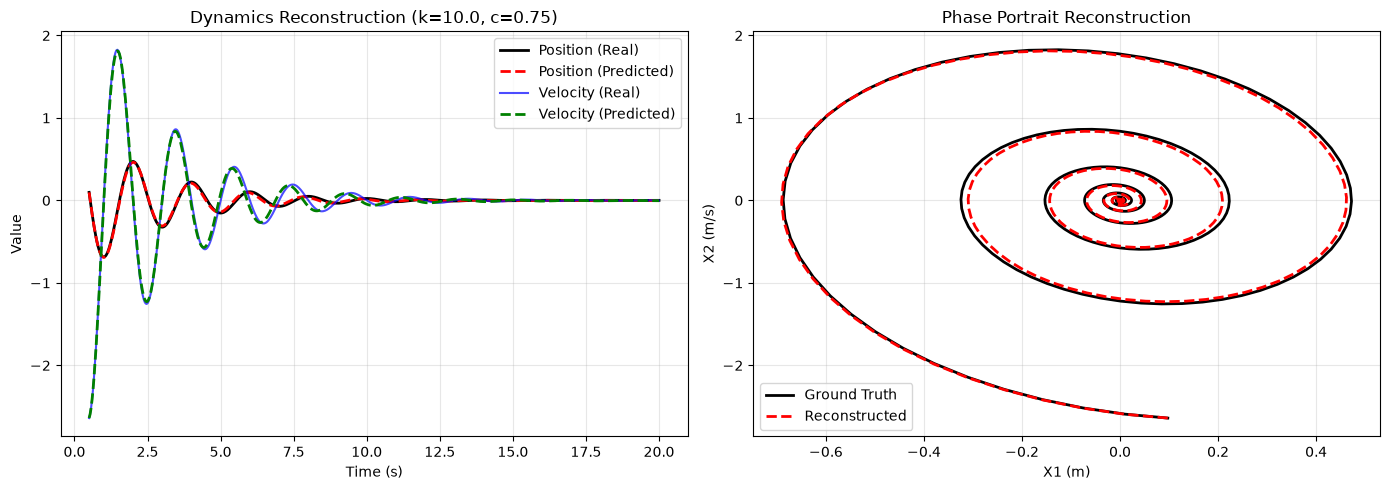

In [156]:
# EVALUATION (A POSTERIORI)
eval_model = TakensNeuralField()
eval_model.load_state_dict(torch.load("param_model_weights.pt"))
eval_model.eval()

k_test, c_test = 10.0, 0.75
X0_test = [1.0, 0.0]

sol_test = solve_ivp(
    lambda t, s: [s[1], (-k_test * s[0] - c_test * s[1]) / m],
    t_span, X0_test, t_eval=t_eval, rtol=1e-9, atol=1e-9
)
X_test_real = torch.tensor(sol_test.y, dtype=torch.float32).T
p_test_norm = (torch.tensor([[k_test, c_test]], dtype=torch.float32) - mean_p) / std_p

max_history_steps = (num_delays - 1) * num_lags
start_idx = max_history_steps

history = [X_test_real[start_idx - k].clone() for k in range(max_history_steps, -1, -1)]
pred_trajectory = [X_test_real[start_idx]]

num_steps = len(t_eval) - start_idx
with torch.no_grad():
    for step in range(num_steps - 1):
        x_n = history[-1]
        elements = [history[-1 - i * num_lags] for i in range(num_delays)]
        raw_emb = torch.cat(elements, dim=0).unsqueeze(0)
        inp_norm = (raw_emb - meanX_tak) / stdX_tak
        
        dX_pred_norm = eval_model(inp_norm, p_test_norm)
        dX_pred = (dX_pred_norm * std_dX + mean_dX).squeeze(0)
        
        x_next = x_n + dt * dX_pred
        
        history.pop(0)
        history.append(x_next)
        pred_trajectory.append(x_next)

pred_trajectory = torch.stack(pred_trajectory).numpy()
valid_t_eval = t_eval[start_idx:]
real_subset = X_test_real[start_idx:].numpy()

# VISUALIZING
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(valid_t_eval, real_subset[:, 0], 'k-', label='Position (Real)', linewidth=2)
axes[0].plot(valid_t_eval, pred_trajectory[:, 0], 'r--', label='Position (Predicted)', linewidth=2)
axes[0].plot(valid_t_eval, real_subset[:, 1], 'b-', label='Velocity (Real)', linewidth=1.5, alpha=0.7)
axes[0].plot(valid_t_eval, pred_trajectory[:, 1], 'g--', label='Velocity (Predicted)', linewidth=2)
axes[0].set_title(f"Dynamics Reconstruction (k={k_test}, c={c_test})")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Value")
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

axes[1].plot(real_subset[:, 0], real_subset[:, 1], 'k-', label='Ground Truth', linewidth=2)
axes[1].plot(pred_trajectory[:, 0], pred_trajectory[:, 1], 'r--', label='Reconstructed', linewidth=2)
axes[1].set_title("Phase Portrait Reconstruction")
axes[1].set_xlabel("X1 (m)")
axes[1].set_ylabel("X2 (m/s)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
